# The University of Azad Jammu and Kashmir

### Department of Software Engineering

# Digital Image Processing Lab

## LAB 04

### Geometric Transformations with Custom Inputs

**Lab Instructor:** Engr. Fahad Nisar  
**Semester:** Fifth  
**Session:** 2024–28 (SE)

**Student Name:** Qurat ul Ain Fatima  
**Roll Number:** 05

---

### Objective

To create a reusable image transformation function that accepts custom values, validates user input, and performs different geometric transformations correctly.

### Practical Overview

In this lab, we will perform the following image transformations using Python and OpenCV:

1. Scaling / Resizing
2. Cropping
3. Flipping
4. Translation
5. Rotation

We will also perform input validation, compare interpolation methods, test identity transformations, and save the transformed images.

### Software Requirements

- Python
- Jupyter Notebook
- OpenCV
- NumPy
- Matplotlib
- Pandas

### Input Image

A kitten garden image will be used as the original input image for performing all geometric transformations.

# Introduction

Geometric transformations are used to change the position, size,
and orientation of an image.

In this lab, we will perform five geometric transformations:
1. Scaling
2. Cropping
3. Flipping
4. Translation
5. Rotation

We will use a kitten garden image to perform these operations.

In [1]:
!pip install opencv-python numpy matplotlib pandas

# Import Libraries

We import different Python libraries to perform image processing.

- OpenCV: For image transformations.
- NumPy: For array operations.
- Matplotlib: For displaying images.
- Pandas: For creating tables.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import math

# Load Image

In this step, we load the original kitten image.

We also check whether the image exists, loads correctly,
and has valid dimensions.

The original image will remain unchanged.

Width: 400
Height: 225
Shape: (225, 400, 3)


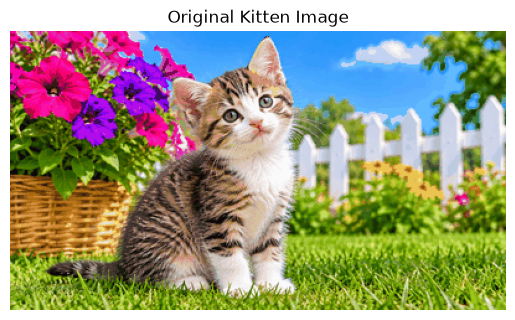

In [3]:
image_path = "image.png"

if not os.path.exists(image_path):
    raise FileNotFoundError("Image not found")

image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image could not be loaded")

original = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = original.shape[:2]

print("Width:", width)
print("Height:", height)
print("Shape:", original.shape)

plt.imshow(original)
plt.title("Original Kitten Image")
plt.axis("off")
plt.show()

# Transform Function

In this step, we create a reusable function named transform().

This function performs five operations:

1. Scaling
2. Cropping
3. Flipping
4. Translation
5. Rotation

It also validates user inputs and returns the transformed image.

In [4]:
def transform(image, operation, **params):

    if not isinstance(image, np.ndarray) or image.size == 0:
        raise ValueError("Invalid or empty image!")

    height, width = image.shape[:2]

    MAX_PIXELS = 20000000

    def get_number(value, name):
        try:
            value = float(value)
        except (TypeError, ValueError):
            raise ValueError(f"{name} must be numeric")

        if not math.isfinite(value):
            raise ValueError(f"{name} must be finite")

        return value

    def get_integer(value, name):
        if isinstance(value, bool) or not isinstance(value, (int, np.integer)):
            raise ValueError(f"{name} must be an integer")
        return int(value)

    operation = operation.lower()

    # 1. SCALING
    if operation == "scale":

        if not {"fx", "fy", "interpolation"}.issubset(params):
            raise ValueError("Missing scaling parameters")

        fx = get_number(params["fx"], "fx")
        fy = get_number(params["fy"], "fy")

        if fx <= 0 or fy <= 0:
            raise ValueError("Scale factors must be positive")

        methods = {
            "nearest": cv2.INTER_NEAREST,
            "bilinear": cv2.INTER_LINEAR,
            "bicubic": cv2.INTER_CUBIC,
            "lanczos": cv2.INTER_LANCZOS4
        }

        interpolation = params["interpolation"]

        if interpolation not in methods:
            raise ValueError("Invalid interpolation method")

        new_width = round(width * fx)
        new_height = round(height * fy)

        if new_width < 1 or new_height < 1:
            raise ValueError("Invalid output dimensions")

        if new_width * new_height > MAX_PIXELS:
            raise ValueError("Output image is too large")

        result = cv2.resize(
            image,
            (new_width, new_height),
            interpolation=methods[interpolation]
        )

    # 2. CROPPING
    elif operation == "crop":

        required = ["left", "top", "right", "bottom"]

        if not all(key in params for key in required):
            raise ValueError("Missing crop parameters")

        left = get_integer(params["left"], "left")
        top = get_integer(params["top"], "top")
        right = get_integer(params["right"], "right")
        bottom = get_integer(params["bottom"], "bottom")

        if not (0 <= left < right <= width):
            raise ValueError("Invalid horizontal coordinates")

        if not (0 <= top < bottom <= height):
            raise ValueError("Invalid vertical coordinates")

        result = image[top:bottom, left:right].copy()

    # 3. FLIPPING
    elif operation == "flip":

        if "direction" not in params:
            raise ValueError("Missing flip direction")

        methods = {
            "horizontal": 1,
            "vertical": 0,
            "both": -1
        }

        direction = params["direction"]

        if direction not in methods:
            raise ValueError("Invalid flip direction")

        result = cv2.flip(image, methods[direction])

    # 4. TRANSLATION
    elif operation == "translate":

        if "tx" not in params or "ty" not in params:
            raise ValueError("Missing translation offsets")

        tx = get_number(params["tx"], "tx")
        ty = get_number(params["ty"], "ty")

        matrix = np.float32([
            [1, 0, tx],
            [0, 1, ty]
        ])

        result = cv2.warpAffine(
            image,
            matrix,
            (width, height),
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=(255, 255, 255)
        )

    # 5. ROTATION
    elif operation == "rotate":

        if "angle" not in params or "expand" not in params:
            raise ValueError("Missing rotation parameters")

        angle = get_number(params["angle"], "angle")
        expand = params["expand"]

        if not isinstance(expand, bool):
            raise ValueError("Expand must be True or False")

        center = (width / 2, height / 2)

        matrix = cv2.getRotationMatrix2D(
            center, angle, 1
        )

        if expand:

            cos = abs(matrix[0, 0])
            sin = abs(matrix[0, 1])

            new_width = int(
                math.ceil(height * sin + width * cos)
            )

            new_height = int(
                math.ceil(height * cos + width * sin)
            )

            if new_width * new_height > MAX_PIXELS:
                raise ValueError("Output image is too large")

            matrix[0, 2] += new_width / 2 - center[0]
            matrix[1, 2] += new_height / 2 - center[1]

        else:
            new_width = width
            new_height = height

        result = cv2.warpAffine(
            image,
            matrix,
            (new_width, new_height),
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=(255, 255, 255)
        )

    else:
        raise ValueError("Unknown operation selected!")

    return result


print("Transform function created successfully!")

Transform function created successfully!


# Scaling / Resizing

Scaling changes the size of an image.

There are three types of scaling:

1. Enlargement: Increases image size.
2. Reduction: Decreases image size.
3. Non-proportional scaling: Changes the aspect ratio.

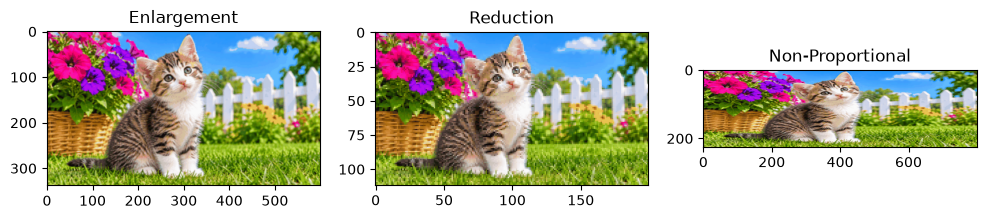

In [5]:
scaled_up = transform(
    original, "scale",
    fx=1.5,
    fy=1.5,
    interpolation="bilinear"
)

scaled_down = transform(
    original, "scale",
    fx=0.5,
    fy=0.5,
    interpolation="bilinear"
)

scaled_non = transform(
    original, "scale",
    fx=2,
    fy=1,
    interpolation="bicubic"
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(scaled_up)
plt.title("Enlargement")

plt.subplot(1, 3, 2)
plt.imshow(scaled_down)
plt.title("Reduction")

plt.subplot(1, 3, 3)
plt.imshow(scaled_non)
plt.title("Non-Proportional")

plt.show()

Enlargement increases the image size.
Reduction decreases the image size.
Non-proportional scaling changes the aspect ratio.

# Cropping

Cropping means selecting and cutting a specific portion
of an image.

It removes unwanted areas and displays the selected region.

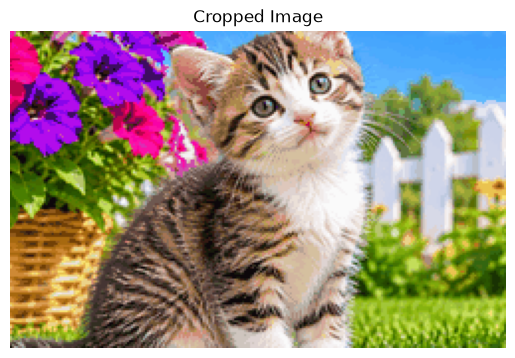

In [6]:
cropped = transform(
    original,
    "crop",
    left=50,
    top=30,
    right=300,
    bottom=190
)

plt.imshow(cropped)
plt.title("Cropped Image")
plt.axis("off")
plt.show()

# Flipping

Flipping changes the direction of an image.

There are three types:

1. Horizontal Flip
2. Vertical Flip
3. Both Directions

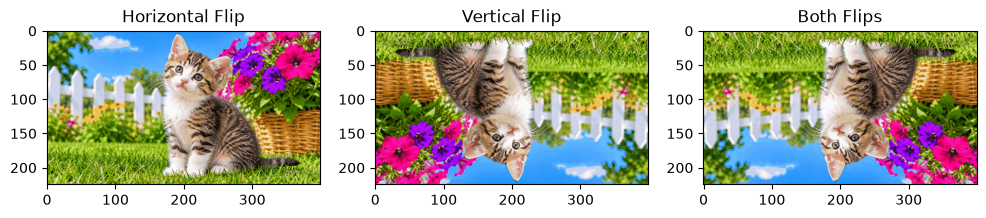

In [7]:
flip_h = transform(
    original, "flip",
    direction="horizontal"
)

flip_v = transform(
    original, "flip",
    direction="vertical"
)

flip_both = transform(
    original, "flip",
    direction="both"
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(flip_h)
plt.title("Horizontal Flip")

plt.subplot(1, 3, 2)
plt.imshow(flip_v)
plt.title("Vertical Flip")

plt.subplot(1, 3, 3)
plt.imshow(flip_both)
plt.title("Both Flips")

plt.show()

# Translation

Translation moves an image from one position to another.

Positive tx moves the image right.
Negative tx moves the image left.
Positive ty moves the image down.
Negative ty moves the image up.

The original canvas size remains unchanged.

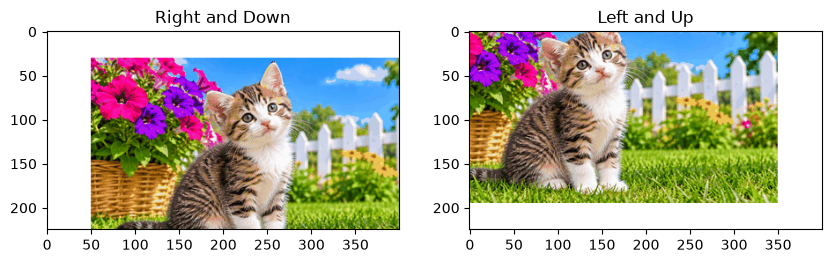

In [8]:
right = transform(
    original, "translate",
    tx=50, ty=30
)

left = transform(
    original, "translate",
    tx=-50, ty=-30
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(right)
plt.title("Right and Down")

plt.subplot(1, 2, 2)
plt.imshow(left)
plt.title("Left and Up")

plt.show()

# Rotation

Rotation means turning an image around its centre.

Positive angles rotate the image counterclockwise.
Negative angles rotate the image clockwise.

Canvas expansion provides extra space for the rotated image.

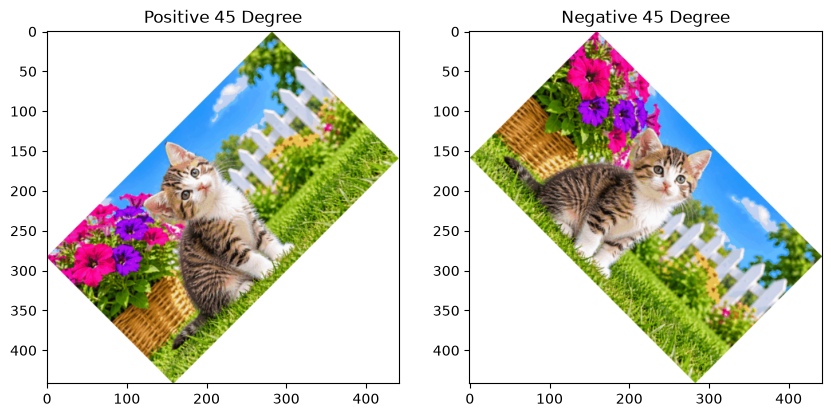

In [9]:
rotate_positive = transform(
    original, "rotate",
    angle=45,
    expand=True
)

rotate_negative = transform(
    original, "rotate",
    angle=-45,
    expand=True
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(rotate_positive)
plt.title("Positive 45 Degree")

plt.subplot(1, 2, 2)
plt.imshow(rotate_negative)
plt.title("Negative 45 Degree")

plt.show()

# Interpolation Comparison

Interpolation is used to calculate pixel values when
an image is resized.

We compare four interpolation methods:

1. Nearest Neighbour
2. Bilinear
3. Bicubic
4. Lanczos

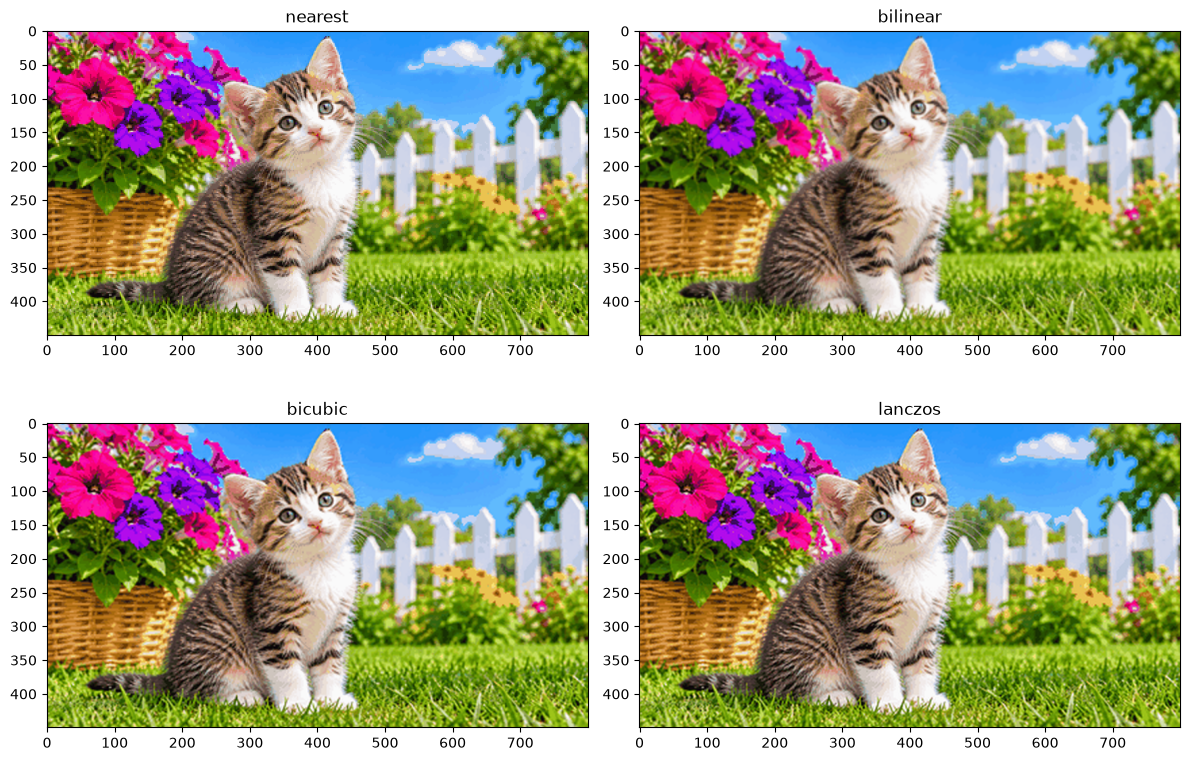

In [10]:
methods = [
    "nearest",
    "bilinear",
    "bicubic",
    "lanczos"
]

plt.figure(figsize=(12, 8))

for i, method in enumerate(methods):

    result = transform(
        original,
        "scale",
        fx=2,
        fy=2,
        interpolation=method
    )

    plt.subplot(2, 2, i+1)
    plt.imshow(result)
    plt.title(method)

plt.tight_layout()
plt.show()

Nearest Neighbour produces blocky pixels.

Bilinear produces smoother results.

Bicubic provides better image quality.

Lanczos preserves sharp image details.

# Input Validation

Input validation checks whether the entered values are correct.

Invalid values are rejected with clear error messages.

We test invalid inputs for all five transformations.

In [11]:
tests = [
    ("scale", {"fx": -1, "fy": 1,
               "interpolation": "bilinear"}),

    ("crop", {"left": 300, "top": 20,
              "right": 100, "bottom": 150}),

    ("flip", {"direction": "diagonal"}),

    ("translate", {"tx": float("nan"), "ty": 20}),

    ("rotate", {"angle": "abc", "expand": True})
]

for operation, params in tests:

    try:
        transform(original, operation, **params)

    except (ValueError, KeyError) as e:
        print(operation, "Invalid Input Rejected:", e)

scale Invalid Input Rejected: Scale factors must be positive
crop Invalid Input Rejected: Invalid horizontal coordinates
flip Invalid Input Rejected: Invalid flip direction
translate Invalid Input Rejected: tx must be finite
rotate Invalid Input Rejected: angle must be numeric


# Identity Transformation

Identity transformation means that the image remains unchanged.

We perform three identity tests:

1. Scaling factors = 1
2. Translation offsets = 0
3. Rotation angle = 0

The output should be the same as the original image.

In [12]:
scale_test = transform(
    original, "scale",
    fx=1, fy=1,
    interpolation="bilinear"
)

translate_test = transform(
    original, "translate",
    tx=0, ty=0
)

rotate_test = transform(
    original, "rotate",
    angle=0,
    expand=False
)

print(np.array_equal(original, scale_test))
print(np.array_equal(original, translate_test))
print(np.array_equal(original, rotate_test))

True
True
True


# Comparison Table

This table shows the expected and actual behaviour
of identity transformations.

In [13]:
data = {
    "Test": [
        "Scaling",
        "Translation",
        "Rotation"
    ],

    "Expected Behaviour": [
        "No Change",
        "No Movement",
        "No Rotation"
    ],

    "Actual Behaviour": [
        "No Change",
        "No Movement",
        "No Rotation"
    ],

    "Result": [
        "Pass",
        "Pass",
        "Pass"
    ]
}

df = pd.DataFrame(data)

display(df)

,Test,Expected Behaviour,Actual Behaviour,Result
0,Scaling,No Change,No Change,Pass
1,Translation,No Movement,No Movement,Pass
2,Rotation,No Rotation,No Rotation,Pass


# Save Transformed Images

In this step, we save all transformed images
in a separate folder named results.

The images are saved in PNG format.

In [14]:
os.makedirs("results", exist_ok=True)

results = {
    "scaled_up": scaled_up,
    "scaled_down": scaled_down,
    "cropped": cropped,
    "flip_horizontal": flip_h,
    "flip_vertical": flip_v,
    "flip_both": flip_both,
    "translated_right": right,
    "translated_left": left,
    "rotated_positive": rotate_positive,
    "rotated_negative": rotate_negative
}

for name, img in results.items():

    cv2.imwrite(
        "results/" + name + ".png",
        cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    )

print("All images saved successfully!")

All images saved successfully!


# Conclusion

In this lab, we learned how to perform geometric
transformations using Python and OpenCV.

We successfully performed scaling, cropping, flipping,
translation, and rotation.

We also learned about interpolation methods,
input validation, and identity transformations.

These operations help us understand how digital images
can be modified and processed.